In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

sim = AerSimulator()
SHOTS = 100

## Original circuit: Bell state
H on qubit 0, then CNOT (control q0, target q1), then measure both qubits.

### Prediction (before running)
The Bell state (|00> + |11>)/sqrt(2) is perfectly correlated, so I expect only 00 and 11, about 50% each. 01 and 10 should not appear.

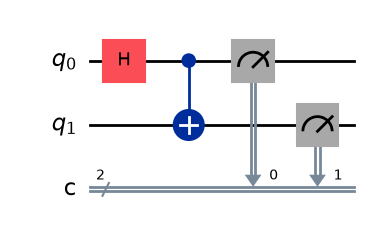

In [2]:
qc_orig = QuantumCircuit(2, 2, name="Original Bell")
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure([0, 1], [0, 1])

display(qc_orig.draw("mpl"))

Original circuit results: {'11': 52, '00': 48}


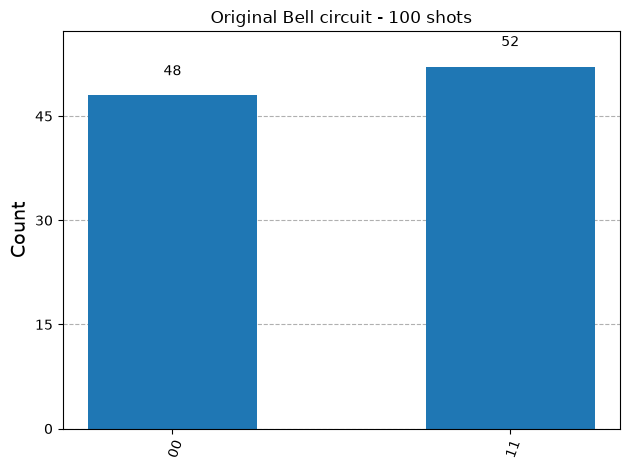

In [3]:
counts_orig = sim.run(qc_orig, shots=SHOTS).result().get_counts()
print("Original circuit results:", counts_orig)
display(plot_histogram(counts_orig, title="Original Bell circuit - 100 shots"))

## Modified circuit: add one X gate on qubit 1 (after the CNOT)

### Prediction (before running)
The X gate flips qubit 1, so (|00> + |11>)/sqrt(2) becomes (|01> + |10>)/sqrt(2).
- The two qubits will now always give different outcomes.
- I expect 01 and 10 at about 50% each.
- 00 and 11 should not appear.
- Total gates before measurement: H, CNOT, X = 3 (limit is 4).

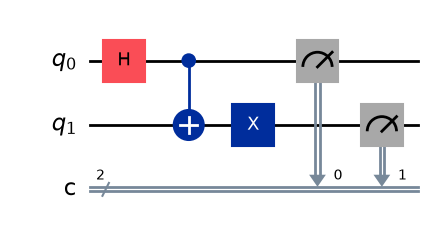

In [4]:
qc_mod = QuantumCircuit(2, 2, name="Modified Bell")
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)          # the one added gate
qc_mod.measure([0, 1], [0, 1])

display(qc_mod.draw("mpl"))

Modified circuit results: {'10': 52, '01': 48}


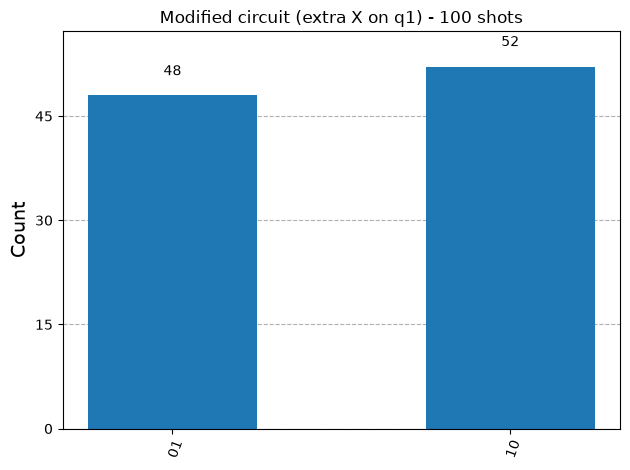

In [5]:
counts_mod = sim.run(qc_mod, shots=SHOTS).result().get_counts()
print("Modified circuit results:", counts_mod)
display(plot_histogram(counts_mod, title="Modified circuit (extra X on q1) - 100 shots"))

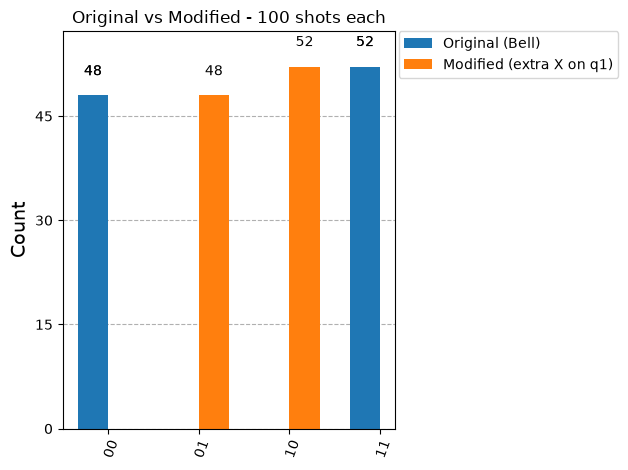

In [6]:
plot_histogram([counts_orig, counts_mod],
               legend=["Original (Bell)", "Modified (extra X on q1)"],
               title="Original vs Modified - 100 shots each")

## Comparison and explanation
- Original circuit: Predicted only 00 and 11 (about 50/50). Actual: {write your counts}. Matched; the qubits always agree.
- Modified circuit: Predicted only 01 and 10 (about 50/50). Actual: {write your counts}. Matched; the qubits now always disagree.

Explanation: The H gate puts qubit 0 in superposition and the CNOT entangles the qubits, giving (|00> + |11>)/sqrt(2). Adding an X gate on qubit 1 flips its value in every term, so the state becomes (|01> + |10>)/sqrt(2). The qubits are still perfectly correlated (entangled), but the correlation changed from same outcomes to opposite outcomes. Each individual qubit is still random (50/50), but knowing one tells you the other. (Qiskit prints bits as q1 q0, so '10' means q1=1, q0=0.)